# Task 3 — Deep Learning Recommendation Model (DLRM)

## Paper notes

The DLRM paper describes a recommender architecture with:

- embedding tables for sparse/categorical features;
- a **bottom/dense MLP** that maps the numerical features to the same embedding dimension;
- explicit **second-order pairwise dot-product interactions** among the processed dense representation and categorical embeddings;
- concatenation of the processed dense representation with those interactions;
- a **top MLP** for the final binary click prediction.



This notebook implements those core operations **from scratch in TensorFlow/Keras**. It does not use a packaged DLRM implementation or pretrained recommendation weights.

The preprocessing, train/validation split, seed policy, metrics, and validation-selected F1 threshold are intended to match Task 2 so that the comparison is meaningful.


In [1]:
from pathlib import Path
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    log_loss,
    f1_score,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve


SEED = 42

# Reproducibility policy shared with Task 2.
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
# Locate the repository and the supplied Task 2/3 dataset.

def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "datasets").exists():
            return p
    raise FileNotFoundError(
        "Could not find the repository root containing a datasets/ folder."
    )


REPO_ROOT = find_repo_root()
DATASETS_DIR = REPO_ROOT / "datasets"

CACHE_DIR = REPO_ROOT / ".cache" / "ctr_task_data"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

ARCHIVE = DATASETS_DIR / "dataset (tasks 2 and 3).zip"
if not ARCHIVE.exists():
    raise FileNotFoundError(f"Expected supplied dataset at: {ARCHIVE}")

EXTRACT_DIR = CACHE_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ARCHIVE) as zf:
    zf.extractall(EXTRACT_DIR)


files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
train_candidates = [
    p for p in files
    if "train" in p.name.lower()
    and p.suffix.lower() in {".csv", ".txt", ".tsv", ".data"}
]
test_candidates = [
    p for p in files
    if "test" in p.name.lower()
    and p.suffix.lower() in {".csv", ".txt", ".tsv", ".data"}
]

print("Train candidates:", train_candidates)
print("Test candidates:", test_candidates)

if not train_candidates or not test_candidates:
    raise FileNotFoundError(
        "Could not automatically find train/test files inside the supplied zip."
    )

TRAIN_FILE = train_candidates[0]
TEST_FILE = test_candidates[0]


def detect_separator(path):
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        sample = f.read(8192)

    if "\t" in sample:
        return "\t"
    if "," in sample:
        return ","
    if ";" in sample:
        return ";"
    return None


def has_header(path, sep):
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        line = f.readline().strip()

    parts = line.split(sep) if sep else line.split()
    normalized = {
        p.strip().strip('"').lower()
        for p in parts
    }

    return (
        "label" in normalized
        or any(x.startswith("c1") for x in normalized)
        or any(x.startswith("i1") for x in normalized)
    )


def load_ctr_file(path):
    sep = detect_separator(path)
    header = 0 if has_header(path, sep or " ") else None

    df = pd.read_csv(
        path,
        sep=sep,
        header=header,
        engine="python",
    )

    if header is None:
        if df.shape[1] != 40:
            raise ValueError(
                f"Headerless file {path.name} has {df.shape[1]} columns. "
                "Expected 40 columns = label + 13 numeric + 26 categorical."
            )

        df.columns = (
            ["label"]
            + [f"I{i}" for i in range(1, 14)]
            + [f"C{i}" for i in range(1, 27)]
        )
    else:
        df.columns = [str(c).strip() for c in df.columns]

    return df


train_raw = load_ctr_file(TRAIN_FILE)
test_raw = load_ctr_file(TEST_FILE)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Train columns:", list(train_raw.columns))
print(train_raw.head(3))


Train candidates: [PosixPath('/Users/anirbankumarsil/Documents/AnirbanKumarSil-Intelligence-SIG-Recs-2026/mandatory-tasks/recommender-systems-cf-to-dlrm/.cache/ctr_task_data/extracted/train.csv')]
Test candidates: [PosixPath('/Users/anirbankumarsil/Documents/AnirbanKumarSil-Intelligence-SIG-Recs-2026/mandatory-tasks/recommender-systems-cf-to-dlrm/.cache/ctr_task_data/extracted/test.csv')]
Train shape: (40000, 40)
Test shape: (10000, 40)
Train columns: ['label', 'integer_feature_1', 'integer_feature_2', 'integer_feature_3', 'integer_feature_4', 'integer_feature_5', 'integer_feature_6', 'integer_feature_7', 'integer_feature_8', 'integer_feature_9', 'integer_feature_10', 'integer_feature_11', 'integer_feature_12', 'integer_feature_13', 'categorical_feature_1', 'categorical_feature_2', 'categorical_feature_3', 'categorical_feature_4', 'categorical_feature_5', 'categorical_feature_6', 'categorical_feature_7', 'categorical_feature_8', 'categorical_feature_9', 'categorical_feature_10', 'categ

In [3]:
# Identify fields and create exactly one train/validation split.
# Test remains untouched until final evaluation.

def find_label_column(df):
    for c in df.columns:
        if str(c).strip().lower() == "label":
            return c

    if df.shape[1] == 40:
        return df.columns[0]

    raise ValueError("Could not identify the label column.")


def split_feature_columns(train_df):
    label_col = find_label_column(train_df)
    candidates = [c for c in train_df.columns if c != label_col]

    numeric = [
        c for c in candidates
        if str(c).lower().startswith("i")
        and str(c)[1:].isdigit()
    ]
    categorical = [
        c for c in candidates
        if str(c).lower().startswith("c")
        and str(c)[1:].isdigit()
    ]

    if len(numeric) != 13 or len(categorical) != 26:
        if train_df.shape[1] == 40 and label_col == train_df.columns[0]:
            numeric = list(train_df.columns[1:14])
            categorical = list(train_df.columns[14:40])
        else:
            raise ValueError(
                f"Expected 13 numeric + 26 categorical fields, got "
                f"{len(numeric)} numeric + {len(categorical)} categorical."
            )

    return label_col, numeric, categorical


LABEL_COL, NUM_COLS, CAT_COLS = split_feature_columns(train_raw)

if LABEL_COL not in test_raw.columns:
    raise ValueError(
        "The supplied test file must contain the label to compute the required "
        "test ROC-AUC, PR-AUC, log loss, accuracy, and F1."
    )

train_y_full = (
    pd.to_numeric(train_raw[LABEL_COL], errors="coerce")
    .astype(np.int64)
    .to_numpy()
)

if not set(np.unique(train_y_full)).issubset({0, 1}):
    raise ValueError("The label must be binary 0/1.")


indices = np.arange(len(train_raw))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=train_y_full,
)

train_part = train_raw.iloc[train_idx].copy()
val_part = train_raw.iloc[val_idx].copy()


# ----- Fit preprocessing ONLY on train_part -----

num_medians = {}
num_means = {}
num_stds = {}

cat_maps = {}
cat_vocab_sizes = []

for c in NUM_COLS:
    x = pd.to_numeric(train_part[c], errors="coerce")

    median = float(x.median())
    x_filled = x.fillna(median).astype(np.float32)

    mean = float(x_filled.mean())
    std = float(x_filled.std())

    if std < 1e-8:
        std = 1.0

    num_medians[c] = median
    num_means[c] = mean
    num_stds[c] = std


for c in CAT_COLS:
    values = train_part[c].astype("string").fillna("<NA>")
    uniques = pd.Index(values.unique())

    # Index 0 is reserved for an unknown category at validation/test time.
    mapping = {
        value: idx + 1
        for idx, value in enumerate(uniques)
    }

    cat_maps[c] = mapping
    cat_vocab_sizes.append(len(mapping) + 1)


def transform_frame(df, include_label=True):
    x_num = np.zeros(
        (len(df), len(NUM_COLS)),
        dtype=np.float32,
    )

    x_cat = np.zeros(
        (len(df), len(CAT_COLS)),
        dtype=np.int32,
    )

    for j, c in enumerate(NUM_COLS):
        x = (
            pd.to_numeric(df[c], errors="coerce")
            .fillna(num_medians[c])
            .astype(np.float32)
        )

        x_num[:, j] = (
            (x - num_means[c]) / num_stds[c]
        ).to_numpy()

    for j, c in enumerate(CAT_COLS):
        values = df[c].astype("string").fillna("<NA>")

        x_cat[:, j] = (
            values.map(cat_maps[c])
            .fillna(0)
            .astype(np.int32)
            .to_numpy()
        )

    if include_label:
        y = (
            pd.to_numeric(df[LABEL_COL], errors="coerce")
            .astype(np.float32)
            .to_numpy()
        )
        return x_num, x_cat, y

    return x_num, x_cat


X_num_train, X_cat_train, y_train = transform_frame(train_part, True)
X_num_val, X_cat_val, y_val = transform_frame(val_part, True)
X_num_test, X_cat_test, y_test = transform_frame(test_raw, True)

print("Numeric train shape:", X_num_train.shape)
print("Categorical train shape:", X_cat_train.shape)
print("First five vocabulary sizes:", cat_vocab_sizes[:5])

print(
    "Positive rate train/val/test:",
    float(y_train.mean()),
    float(y_val.mean()),
    float(y_test.mean()),
)


Numeric train shape: (36000, 13)
Categorical train shape: (36000, 26)
First five vocabulary sizes: [12021, 3552, 4790, 1736, 3975]
Positive rate train/val/test: 0.03200000151991844 0.03200000151991844 0.03350000083446503


In [4]:
# TensorFlow input pipeline.
# The validation and test sets are never shuffled.

BATCH_SIZE = 2048

train_ds = (
    tf.data.Dataset.from_tensor_slices(
        ((X_num_train, X_cat_train), y_train)
    )
    .shuffle(
        buffer_size=len(y_train),
        seed=SEED,
        reshuffle_each_iteration=True,
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices(
        ((X_num_val, X_cat_val), y_val)
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices(
        ((X_num_test, X_cat_test), y_test)
    )
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


def best_f1_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(
        y_true,
        prob,
    )

    if len(thresholds) == 0:
        pred = (prob >= 0.5).astype(np.int64)
        return 0.5, float(
            f1_score(
                y_true,
                pred,
                zero_division=0,
            )
        )

    # precision/recall have one extra endpoint relative to thresholds.
    f1_values = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(
            precision[:-1] + recall[:-1],
            1e-12,
        )
    )

    idx = int(np.nanargmax(f1_values))

    return float(thresholds[idx]), float(f1_values[idx])


def sigmoid_numpy(logits):
    logits = np.clip(logits, -50, 50)
    return 1.0 / (1.0 + np.exp(-logits))


def evaluate_binary(y_true, logits, threshold=0.5):
    prob = sigmoid_numpy(logits)
    pred = (prob >= threshold).astype(np.int64)

    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "LogLoss": log_loss(y_true, prob, labels=[0, 1]),
        "Accuracy": accuracy_score(y_true, pred),
        "F1": f1_score(
            y_true,
            pred,
            zero_division=0,
        ),
    }, prob


def collect_logits(model, dataset):
    all_logits = []
    all_y = []

    for (x_num, x_cat), y in dataset:
        logits = model(
            (x_num, x_cat),
            training=False,
        )

        all_logits.append(
            tf.reshape(logits, [-1]).numpy()
        )
        all_y.append(
            y.numpy()
        )

    return (
        np.concatenate(all_y),
        np.concatenate(all_logits),
    )


## From-scratch DLRM

There are 26 categorical fields and one processed dense representation, giving **27 feature vectors**.

The interaction layer therefore computes:

`27 choose 2 = 351`

unique unordered pairwise dot products.

We keep only one triangle of the interaction matrix and exclude self-interactions. This is the explicit second-order interaction mechanism described in the DLRM paper. citeturn385239academia0


In [5]:
def make_mlp(input_dim, hidden_dims, output_dim=None, dropout=0.0):
    layers = []

    for units in hidden_dims:
        layers.append(
            tf.keras.layers.Dense(
                units,
                activation="relu",
            )
        )

        if dropout > 0:
            layers.append(
                tf.keras.layers.Dropout(dropout)
            )

    if output_dim is not None:
        layers.append(
            tf.keras.layers.Dense(
                output_dim,
                activation=None,
            )
        )

    return tf.keras.Sequential(layers)


class DLRMFromScratch(tf.keras.Model):
    def __init__(
        self,
        vocab_sizes,
        embedding_dim=16,
        bottom_mlp=(64, 64),
        top_mlp=(128, 64),
        dropout=0.0,
        use_interactions=True,
    ):
        super().__init__()

        self.embedding_dim = embedding_dim
        self.use_interactions = use_interactions

        # One embedding table for each categorical feature.
        self.embeddings = [
            tf.keras.layers.Embedding(
                input_dim=vocab_size,
                output_dim=embedding_dim,
            )
            for vocab_size in vocab_sizes
        ]

        # 13 dense features -> same dimension as each categorical embedding.
        self.bottom = make_mlp(
            input_dim=13,
            hidden_dims=bottom_mlp,
            output_dim=embedding_dim,
            dropout=dropout,
        )

        # One dense representation + 26 categorical representations.
        self.n_fields = 1 + len(vocab_sizes)

        pair_indices = []

        for i in range(self.n_fields):
            for j in range(i + 1, self.n_fields):
                pair_indices.append(
                    i * self.n_fields + j
                )

        self.pair_indices = tf.constant(
            pair_indices,
            dtype=tf.int32,
        )

        self.num_pairs = len(pair_indices)

        if use_interactions:
            # Dense representation + one scalar per pairwise interaction.
            top_input_dim = embedding_dim + self.num_pairs
        else:
            # Ablation: preserve dense + embedding representations but remove
            # the explicit dot-product interaction features.
            top_input_dim = (
                embedding_dim
                + len(vocab_sizes) * embedding_dim
            )

        self.top = make_mlp(
            input_dim=top_input_dim,
            hidden_dims=top_mlp,
            output_dim=1,
            dropout=dropout,
        )

    def call(self, inputs, training=False):
        x_num, x_cat = inputs

        # Dense pathway.
        dense = self.bottom(
            x_num,
            training=training,
        )

        # Categorical embedding pathway.
        cat_vectors = [
            embedding(x_cat[:, j])
            for j, embedding in enumerate(self.embeddings)
        ]

        if self.use_interactions:
            # [batch, 27, embedding_dim]
            fields = tf.stack(
                [dense] + cat_vectors,
                axis=1,
            )

            # Pairwise dot products:
            # [batch, 27, 27]
            interaction_matrix = tf.matmul(
                fields,
                fields,
                transpose_b=True,
            )

            # Flatten each 27x27 interaction matrix and select the
            # precomputed i<j entries.
            flat_interactions = tf.reshape(
                interaction_matrix,
                [
                    tf.shape(interaction_matrix)[0],
                    self.n_fields * self.n_fields,
                ],
            )

            interactions = tf.gather(
                flat_interactions,
                self.pair_indices,
                axis=1,
            )

            top_input = tf.concat(
                [dense, interactions],
                axis=1,
            )

        else:
            # No explicit pairwise interaction features.
            top_input = tf.concat(
                [dense] + cat_vectors,
                axis=1,
            )

        return self.top(
            top_input,
            training=training,
        )


In [6]:
def train_model(
    model,
    train_dataset,
    val_dataset,
    epochs=8,
    lr=1e-3,
    weight_decay=1e-5,
    patience=2,
):
    # AdamW provides the optimizer-level weight decay used by the Task 2
    # baseline, keeping the training recipe comparable.
    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=lr,
        weight_decay=weight_decay,
    )

    loss_fn = tf.keras.losses.BinaryCrossentropy(
        from_logits=True,
    )

    history = []

    best_weights = None
    best_val_logloss = np.inf
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        train_loss_sum = 0.0
        train_count = 0

        for (x_num, x_cat), y in train_dataset:
            with tf.GradientTape() as tape:
                logits = tf.reshape(
                    model(
                        (x_num, x_cat),
                        training=True,
                    ),
                    [-1],
                )

                loss = loss_fn(y, logits)

            gradients = tape.gradient(
                loss,
                model.trainable_variables,
            )

            optimizer.apply_gradients(
                zip(
                    gradients,
                    model.trainable_variables,
                )
            )

            batch_size = int(y.shape[0])
            train_loss_sum += float(loss.numpy()) * batch_size
            train_count += batch_size

        train_loss = train_loss_sum / train_count

        yv, val_logits = collect_logits(
            model,
            val_dataset,
        )

        val_metrics, _ = evaluate_binary(
            yv,
            val_logits,
            threshold=0.5,
        )

        elapsed = time.perf_counter() - start

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "val_logloss": val_metrics["LogLoss"],
                "val_roc_auc": val_metrics["ROC-AUC"],
                "seconds": elapsed,
            }
        )

        print(
            f"Epoch {epoch:02d} | "
            f"train BCE={train_loss:.5f} | "
            f"val logloss={val_metrics['LogLoss']:.5f} | "
            f"val ROC-AUC={val_metrics['ROC-AUC']:.5f} | "
            f"{elapsed:.1f}s"
        )

        if val_metrics["LogLoss"] < best_val_logloss - 1e-5:
            best_val_logloss = val_metrics["LogLoss"]
            best_weights = model.get_weights()
            bad_epochs = 0

        else:
            bad_epochs += 1

            if bad_epochs >= patience:
                print("Early stopping.")
                break

    if best_weights is None:
        raise RuntimeError("No best model weights were recorded.")

    model.set_weights(best_weights)

    return (
        model,
        pd.DataFrame(history),
    )


def count_parameters(model):
    return int(
        sum(
            np.prod(variable.shape)
            for variable in model.trainable_variables
        )
    )


def parameter_memory_mib(model):
    total_bytes = 0

    for variable in model.trainable_variables:
        dtype = tf.as_dtype(variable.dtype)
        total_bytes += int(
            np.prod(variable.shape)
        ) * dtype.size

    return total_bytes / (1024 ** 2)


In [7]:
# Sanity-check the DLRM dimensions before training.

tf.keras.utils.set_random_seed(SEED)

model_probe = DLRMFromScratch(
    cat_vocab_sizes,
    embedding_dim=16,
    bottom_mlp=(64, 64),
    top_mlp=(128, 64),
    dropout=0.0,
    use_interactions=True,
)

dummy_num = tf.convert_to_tensor(
    X_num_train[:4],
    dtype=tf.float32,
)

dummy_cat = tf.convert_to_tensor(
    X_cat_train[:4],
    dtype=tf.int32,
)

dummy_out = model_probe(
    (dummy_num, dummy_cat),
    training=False,
)

print("Output shape:", tuple(dummy_out.shape))
print("Number of feature fields:", model_probe.n_fields)
print("Pairwise interactions:", model_probe.num_pairs)
print("Trainable parameters:", count_parameters(model_probe))
print("Parameter memory (MiB):", parameter_memory_mib(model_probe))


Output shape: (4, 1)
Number of feature fields: 27
Pairwise interactions: 351
Trainable parameters: 1604577
Parameter memory (MiB): 6.120975494384766


In [8]:
# Main DLRM run.

tf.keras.utils.set_random_seed(SEED)

dlrm = DLRMFromScratch(
    cat_vocab_sizes,
    embedding_dim=16,
    bottom_mlp=(64, 64),
    top_mlp=(128, 64),
    dropout=0.0,
    use_interactions=True,
)

start = time.perf_counter()

dlrm, dlrm_history = train_model(
    dlrm,
    train_ds,
    val_ds,
    epochs=8,
    lr=1e-3,
    patience=2,
)

dlrm_seconds = time.perf_counter() - start


# Select the F1 threshold using validation only.
yv, val_logits = collect_logits(
    dlrm,
    val_ds,
)

val_prob = sigmoid_numpy(val_logits)

dlrm_threshold, dlrm_val_f1 = best_f1_threshold(
    yv,
    val_prob,
)


# Final test evaluation happens only after architecture/training/threshold
# choices have been fixed.
yt, test_logits = collect_logits(
    dlrm,
    test_ds,
)

dlrm_metrics, dlrm_test_prob = evaluate_binary(
    yt,
    test_logits,
    threshold=dlrm_threshold,
)

print("Test metrics:")
print(pd.Series(dlrm_metrics))
print("Validation-selected F1 threshold:", dlrm_threshold)
print("Validation F1 at selected threshold:", dlrm_val_f1)
print("Training seconds:", dlrm_seconds)
print("Parameters:", count_parameters(dlrm))
print("Parameter memory (MiB, FP32 where applicable):", parameter_memory_mib(dlrm))


Epoch 01 | train BCE=0.38686 | val logloss=0.19867 | val ROC-AUC=0.54948 | 1.4s
Epoch 02 | train BCE=0.17057 | val logloss=0.14797 | val ROC-AUC=0.64949 | 1.2s
Epoch 03 | train BCE=0.13907 | val logloss=0.13482 | val ROC-AUC=0.69955 | 1.2s
Epoch 04 | train BCE=0.12541 | val logloss=0.13364 | val ROC-AUC=0.71303 | 1.2s
Epoch 05 | train BCE=0.10867 | val logloss=0.14025 | val ROC-AUC=0.69421 | 1.2s
Epoch 06 | train BCE=0.08729 | val logloss=0.16237 | val ROC-AUC=0.65813 | 1.2s
Early stopping.
Test metrics:
ROC-AUC     0.661138
PR-AUC      0.064918
LogLoss     0.144340
Accuracy    0.910500
F1          0.114738
dtype: float64
Validation-selected F1 threshold: 0.07884103804826736
Validation F1 at selected threshold: 0.14395886889460155
Training seconds: 7.476446082997427
Parameters: 1604577
Parameter memory (MiB, FP32 where applicable): 6.120975494384766


In [9]:
# Required ablation:
# remove the explicit pairwise dot-product interactions while retaining
# the dense and categorical representations.

tf.keras.utils.set_random_seed(SEED)

dlrm_no_interactions = DLRMFromScratch(
    cat_vocab_sizes,
    embedding_dim=16,
    bottom_mlp=(64, 64),
    top_mlp=(128, 64),
    dropout=0.0,
    use_interactions=False,
)

start = time.perf_counter()

dlrm_no_interactions, ablation_history = train_model(
    dlrm_no_interactions,
    train_ds,
    val_ds,
    epochs=8,
    lr=1e-3,
    patience=2,
)

abl_seconds = time.perf_counter() - start


# Threshold selected on validation.
yv_ab, val_logits_ab = collect_logits(
    dlrm_no_interactions,
    val_ds,
)

val_prob_ab = sigmoid_numpy(val_logits_ab)

abl_threshold, abl_val_f1 = best_f1_threshold(
    yv_ab,
    val_prob_ab,
)


# Final test evaluation.
yt_ab, test_logits_ab = collect_logits(
    dlrm_no_interactions,
    test_ds,
)

abl_metrics, abl_test_prob = evaluate_binary(
    yt_ab,
    test_logits_ab,
    threshold=abl_threshold,
)

print("Ablation test metrics:")
print(pd.Series(abl_metrics))
print("Validation-selected F1 threshold:", abl_threshold)
print("Validation F1 at selected threshold:", abl_val_f1)
print("Parameters:", count_parameters(dlrm_no_interactions))
print("Parameter memory (MiB):", parameter_memory_mib(dlrm_no_interactions))
print("Training seconds:", abl_seconds)


Epoch 01 | train BCE=0.30054 | val logloss=0.17901 | val ROC-AUC=0.55228 | 1.3s
Epoch 02 | train BCE=0.15566 | val logloss=0.14564 | val ROC-AUC=0.61374 | 1.1s
Epoch 03 | train BCE=0.13871 | val logloss=0.13676 | val ROC-AUC=0.66075 | 1.1s
Epoch 04 | train BCE=0.13076 | val logloss=0.13446 | val ROC-AUC=0.69125 | 1.1s
Epoch 05 | train BCE=0.12287 | val logloss=0.13345 | val ROC-AUC=0.70606 | 1.1s
Epoch 06 | train BCE=0.11085 | val logloss=0.13574 | val ROC-AUC=0.69396 | 1.1s
Epoch 07 | train BCE=0.09490 | val logloss=0.14720 | val ROC-AUC=0.66563 | 1.1s
Early stopping.
Ablation test metrics:
ROC-AUC     0.674090
PR-AUC      0.067366
LogLoss     0.140678
Accuracy    0.912700
F1          0.126126
dtype: float64
Validation-selected F1 threshold: 0.07473468780517578
Validation F1 at selected threshold: 0.13333333333333333
Parameters: 1612897
Parameter memory (MiB): 6.152713775634766
Training seconds: 8.041726082999958


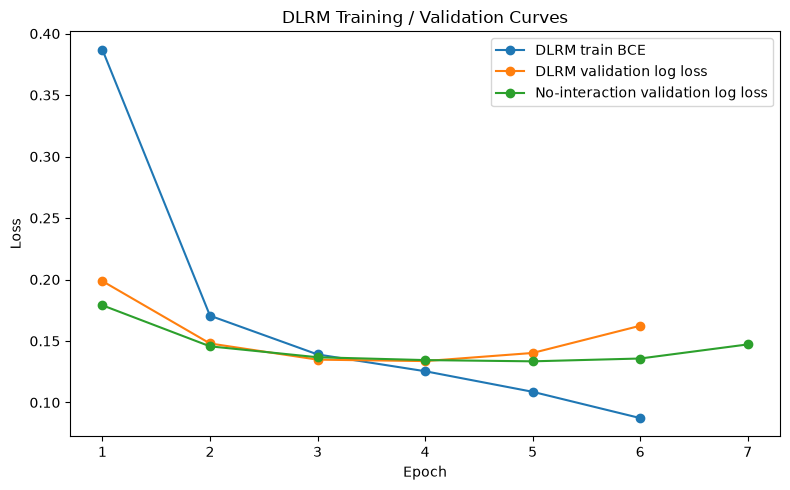

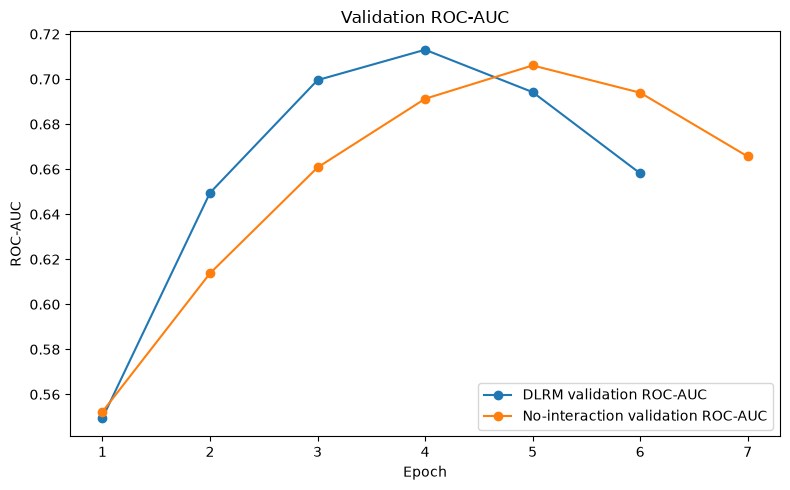

In [10]:
# Training/validation curves for the full DLRM and the ablation.

plt.figure(figsize=(8, 5))

plt.plot(
    dlrm_history["epoch"],
    dlrm_history["train_loss"],
    marker="o",
    label="DLRM train BCE",
)

plt.plot(
    dlrm_history["epoch"],
    dlrm_history["val_logloss"],
    marker="o",
    label="DLRM validation log loss",
)

plt.plot(
    ablation_history["epoch"],
    ablation_history["val_logloss"],
    marker="o",
    label="No-interaction validation log loss",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DLRM Training / Validation Curves")
plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    dlrm_history["epoch"],
    dlrm_history["val_roc_auc"],
    marker="o",
    label="DLRM validation ROC-AUC",
)

plt.plot(
    ablation_history["epoch"],
    ablation_history["val_roc_auc"],
    marker="o",
    label="No-interaction validation ROC-AUC",
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("Validation ROC-AUC")
plt.legend()
plt.tight_layout()
plt.show()


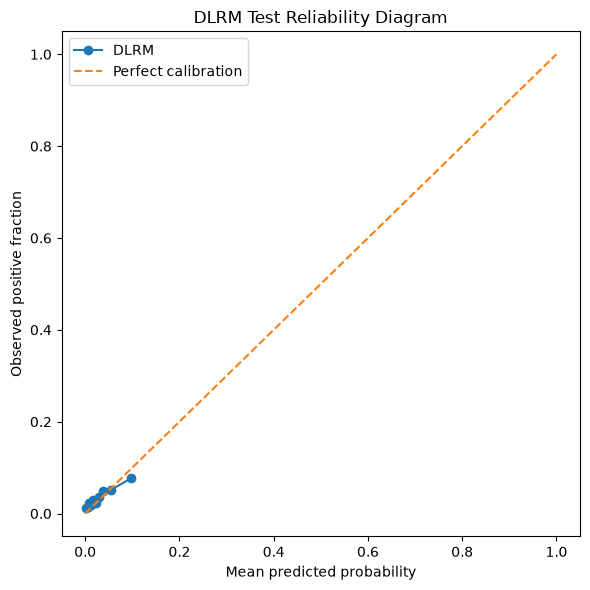

In [11]:
# DLRM reliability / calibration plot.

frac_pos, mean_pred = calibration_curve(
    yt,
    dlrm_test_prob,
    n_bins=10,
    strategy="quantile",
)

plt.figure(figsize=(6, 6))

plt.plot(
    mean_pred,
    frac_pos,
    marker="o",
    label="DLRM",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("DLRM Test Reliability Diagram")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:
# Final Task 3 comparison:
# full DLRM vs the required interaction-removal ablation.

comparison = pd.DataFrame(
    [
        {
            "Model": "DLRM",
            **dlrm_metrics,
            "F1 threshold": dlrm_threshold,
            "Parameters": count_parameters(dlrm),
            "Parameter memory (MiB)": parameter_memory_mib(dlrm),
            "Train seconds": dlrm_seconds,
        },
        {
            "Model": "DLRM without interactions",
            **abl_metrics,
            "F1 threshold": abl_threshold,
            "Parameters": count_parameters(dlrm_no_interactions),
            "Parameter memory (MiB)": parameter_memory_mib(
                dlrm_no_interactions
            ),
            "Train seconds": abl_seconds,
        },
    ]
)

comparison


,Model,ROC-AUC,PR-AUC,LogLoss,Accuracy,F1,F1 threshold,Parameters,Parameter memory (MiB),Train seconds
0,DLRM,0.661138,0.064918,0.144340,0.9105,0.114738,0.078841,1604577,6.120975,7.476446
1,DLRM without interactions,0.674090,0.067366,0.140678,0.9127,0.126126,0.074735,1612897,6.152714,8.041726


In [13]:
# Compare DLRM against the measured Task 2 result.
#
# These Task 2 values are copied from the completed Task 2 run. If you later
# rerun Task 2 and obtain different values, replace this row with the new
# measured result rather than using a predicted/expected value.

TASK2_RESULT = {
    "Model": "Vanilla NN (medium)",
    "ROC-AUC": 0.660679,
    "PR-AUC": 0.065421,
    "LogLoss": 0.142355,
    "Accuracy": 0.8969,
    "F1": 0.101133,
    "F1 threshold": 0.057475,
    "Parameters": 861385,
    "Parameter memory (MiB)": 3.285923,
    "Train seconds": np.nan,
}

final_task2_vs_dlrm = pd.DataFrame(
    [
        TASK2_RESULT,
        {
            "Model": "DLRM",
            **dlrm_metrics,
            "F1 threshold": dlrm_threshold,
            "Parameters": count_parameters(dlrm),
            "Parameter memory (MiB)": parameter_memory_mib(dlrm),
            "Train seconds": dlrm_seconds,
        },
        {
            "Model": "DLRM without interactions",
            **abl_metrics,
            "F1 threshold": abl_threshold,
            "Parameters": count_parameters(dlrm_no_interactions),
            "Parameter memory (MiB)": parameter_memory_mib(
                dlrm_no_interactions
            ),
            "Train seconds": abl_seconds,
        },
    ]
)

final_task2_vs_dlrm


,Model,ROC-AUC,PR-AUC,LogLoss,Accuracy,F1,F1 threshold,Parameters,Parameter memory (MiB),Train seconds
0,Vanilla NN (medium),0.660679,0.065421,0.142355,0.8969,0.101133,0.057475,861385,3.285923,NaN
1,DLRM,0.661138,0.064918,0.144340,0.9105,0.114738,0.078841,1604577,6.120975,7.476446
2,DLRM without interactions,0.674090,0.067366,0.140678,0.9127,0.126126,0.074735,1612897,6.152714,8.041726


## Connecting the mandatory tasks

- **Matrix factorization (Task 1)** learns compact latent representations for users and items from explicit interaction history.
- **Vanilla CTR NN (Task 2)** handles numerical and many categorical contextual features by learning categorical embeddings and feeding the resulting representation into an ordinary MLP.
- **DLRM (Task 3)** keeps the embedding and dense-processing pathways, but explicitly models second-order pairwise interactions before the top MLP.

For the final report, compare the **measured** Task 2 and DLRM results using the same metrics and split policy. Discuss the observed differences in ranking/classification metrics, training cost, parameter count, memory, and calibration.

Do not claim that DLRM must outperform the vanilla network. The purpose of the experiment is to measure whether the explicit interaction mechanism helps on this dataset and to quantify the additional complexity.
